Here I try to learn the control fields of a time-dependent Hamiltonian from a set of observable data.

In [2]:
#import random
import torch as tc
import numpy as np
import qutip as qt
import pandas as pd
#from scipy.sparse import csr_array, lil_array
import matplotlib.pyplot as plt
import torch.nn as nn
#import time as tm
#from torch.func import jacrev, vmap
from tqdm import tqdm
import sys
from typing import List
import os
sys.path.insert(0, '../../PopsCtrl/')
import function as my

# Set this to the number of physical cores you will use
num_threads = 10
tc.set_num_threads(num_threads)
tc.set_num_interop_threads(num_threads)
print(f"Threads set to: {tc.get_num_threads()}")

Threads set to: 10


Run this to use a single-qubit system.

In [3]:
Nqb = 1 #Number of qubits

nval = 2 #Number of states to be used for further validation. Won't be used during training
ThreeStates = False# USe it to implement or not the 3 initial states described in doi:10.1088/1367-2630/16/5/055012
loaded = False# Set True to load control fields from a file
filesctrl = "../../data_files/Control/StchKr_Had_1noi.csv"
FouFeat = True# Whether or not to use Fourier features

if (Nqb == 1):
  Liedim = 3#Dimension of the Lie-algebra
  nist = 5# NUmber of initial states
  Nfield=3# Number of control fields
  Nedo= Liedim*nist# Number of differential equations to solve
  Ncoll = 2#Number of collapse operators
else:
  Liedim = 15#Dimension of the Lie-algebra
  nist = 5# NUmber of initial states
  Nfield=6# Number of control fields
  Nedo= Liedim*nist# Number of differential equations to solve
  Ncoll = 4#Number of collapse operators

In [ ]:
if loaded:
  loadedfields = pd.read_csv(filesctrl)

  t_points =  loadedfields.iloc[::2,0].to_numpy()
  dt = t_points[1]-t_points[0]
  t_points = t_points - 0.5*dt*np.ones_like(t_points)
  tfinal      = t_points[-1] + dt
  t_points = np.concatenate([t_points, np.array([tfinal])])
  N           = len(t_points)

  ctrls = loadedfields.iloc[::2,1:4].to_numpy()
  ctrls = np.concatenate([ctrls, np.zeros((1,Nfield))], axis=0)
  ctrls[-1,:] = 1.5*ctrls[-2,:] - 0.5*ctrls[-3,:]
else:
  tfinal = 2.#2.52*np.pi
  N = 101#Number of collocation points

  def Field(t):
      return ( 1.5* np.sin(2.0 * t) - 0.3*np.cos(3* t - 0.5) + 0.4*np.sin(7.0 * t)
          )*np.sin(np.pi*t/tfinal)**2

  np.random.seed(104711)# Use a seed for replicability of the results.

  nfreq = 4# Number of frequencies to generate a Fourier series

  def gen_rdn_Fourier(t, nfreq):
      w = np.random.normal(0. , 0.5, nfreq)# Frequencies
      phi = np.random.uniform(-0.5*np.pi , 0.5*np.pi, nfreq)# Phase shifts
      b = np.random.uniform(0. , 1., nfreq)# Amplitudes

      prod = np.pi*w[None,:]*t.reshape(-1,1)

      return np.sin(prod + phi[None, :]) @ b

  t_points = np.linspace(0., tfinal, N)

  ctrls = np.zeros((len(t_points), Nfield))

  if (Nqb == 1):
      ctrls[:,0] = Field(t_points)
      if (Nfield > 1):
        ctrls[:,1] = np.cos(np.pi*t_points/tfinal)
        if (Nfield > 2):
            ctrls[:,2] = 0.5*(-1 + np.sin(np.pi*t_points/tfinal))
      #ctrls[:,1] = -0.5 * np.ones_like(t_points)
  else:
      for i in range(Nfield):
          ctrls[:,i] = gen_rdn_Fourier(t_points, nfreq)

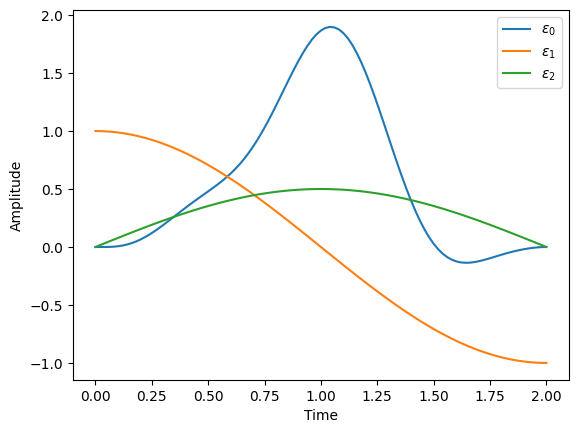

In [5]:
fig, ax = plt.subplots()
for i in range(Nfield):
  ax.plot(t_points, ctrls[:,i], label=fr"$\epsilon_{i}$")

ax.set_xlabel("Time")
ax.set_ylabel("Amplitude")
ax.legend()
plt.show()

In [6]:
def inv_sigmoid(y):
    eps = 1e-6
    y = tc.clamp(y, eps, 1 - eps)
    return tc.log(y / (1 - y))

class FourierFeatures(nn.Module):
    # Uncomment the following code to use uniform frequency distribution and comment the code below it
    """
    def __init__(self, n_freq, f_max, trainable=True):
        super().__init__()
        self.f_max = f_max
        self.raw_freq = nn.Parameter(tc.randn(n_freq), requires_grad=trainable)

        f0 = tc.linspace(0.05 * f_max, 0.95 * f_max, n_freq)
        raw0 = inv_sigmoid(f0 / f_max)

        self.raw_freq = nn.Parameter(raw0.clone(), requires_grad=trainable)

    def get_freq(self):
        return self.f_max * tc.sigmoid(self.raw_freq)

    def forward(self, t):
        if t.dim() == 1:
            t = t.unsqueeze(1)   # (batch,1)

        freq = self.get_freq().unsqueeze(0)   # (1,n_freq)
        arg = 2.0 * np.pi * t * freq        # (batch,n_freq)

        return tc.cat([tc.sin(arg), tc.cos(arg)], dim=1)
    """
    def __init__(self, m, sigma=10.0, trainable=False):
        super().__init__()
        B = tc.randn(m, 1) * sigma
        self.B = nn.Parameter(B, requires_grad=trainable)

    def forward(self, t):
        if t.dim() == 1:
            t = t[:, None]
        x = 2 * np.pi * t @ self.B.T
        return tc.cat([tc.sin(x), tc.cos(x)], dim=-1)
    
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=32, f_max=10.0, trainable=True):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            #self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=True)
            self.ff = FourierFeatures(m=n_freq, sigma=f_max, trainable=trainable)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater)**2)

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

In [7]:
if FouFeat:
        neuronio = [128, 128]

        X_vector = Rede(
        neuronio=neuronio,
        input_=1,
        output_=Nedo + Nfield,
        activation=[SIN()]*len(neuronio),
        creat_p=True,
        N_of_paramater=Ncoll,
        use_fourier=True,
        n_freq=12,
        f_max=1.0,
        trainable=False
        )

        opt = tc.optim.Adam(X_vector.parameters(),
                lr = 0.001)
        time =  tc.linspace(
                0,
                tfinal,
                N,
                dtype   = tc.float32,
                requires_grad = True).reshape((-1, 1))
else:
        neuronio = [256, 256]#[128,128,128] didn't work
        X_vector   = my.Rede(
        neuronio    = neuronio,
        input_      = 1,
        output_     = Nedo+Nfield,
        activation  =[tc.nn.Tanh()]*len(neuronio),
        creat_p     =True,
        N_of_paramater= Ncoll)
        opt = tc.optim.Adam(X_vector.parameters(),
                lr = 0.001)
        time =  tc.linspace(
                0,
                tfinal,
                N,
                dtype   = tc.float32,
                requires_grad = True).reshape((-1, 1))
        #index_data = np.random.randint(0,N,size=100)
        #X_vector.parametro

The following function computes the residuals of the Heisenberg equations for the mean values of the observables, and the normalization loss. We compute them as

$$
\frac{d\langle \alpha _{\nu } \rangle }{dt} =  \sum \limits _{k} \gamma_k d_{k\nu} + \sum _{\eta}\left[\left(\sum _{\mu } J_{\mu }( t) \ c_{\mu \nu \eta }\right) +\sum _{k} \gamma _{k} \ b_{k\nu \eta }\right] \langle \alpha _{\eta } \rangle,
$$

where $\alpha _{\nu }$ are the observables (forming a Lie-algebra), $J_{\nu }( t)$ is the control field corersponding to $\alpha _{\nu }$ in the expansion $H(t)=\sum\limits _{\nu } J_{\nu }( t) \alpha _{\nu }$ of the Hamiltonian, $\gamma_k$ are the decay rates, and the coefficients $c_{\mu \nu \eta }$, $\ b_{k\nu \eta }$, and $d_{k\nu}$ correspond to the expansions

$$
 \begin{array}{l}
i[ \alpha _{\mu } ,\alpha _{\nu }] =\sum\limits _{\eta } c_{\mu \nu \eta } \ \alpha _{\eta } ,\\
L_{k}^{\dagger } \alpha _{\nu } L_{k} -\frac{1}{2}\left\{L_{k}^{\dagger } L_{k} ,\alpha _{\nu }\right\} = d_{k\nu} I + \sum\limits _{\eta } b_{k\nu \eta } \ \alpha _{\eta },
\end{array}
$$

with $L_{k}$ the Liouville operators.

In [8]:
if (Nqb==1):
    def calculate_physics_loss(commcoeff: tc.Tensor, collcoef: tc.Tensor, cnstcoef: tc.Tensor, Gammas: tc.Tensor, Obs: tc.Tensor, derivs: tc.Tensor, Jt: List[tc.Tensor]):
        dim = Jt.shape[1]
        Nist = int(derivs.shape[1]/dim)
        #-----Calculate the matrix corresponding to the right-hand side of the EDOs----------------
        A = tc.tensordot(Jt, commcoeff, dims=([1], [0])) + tc.tensordot(Gammas, collcoef, dims=([0], [0]))
        b = Gammas @ cnstcoef
        rhs_vec = tc.zeros_like(derivs)

        for i in range(Nist):
            rhs_vec[:, i*dim:(i+1)*dim] = b + tc.bmm(A, Obs[:, i*dim:(i+1)*dim].unsqueeze(-1)).squeeze(-1)
        # Residual squared, summed over all components
        loss_edo = ((derivs - rhs_vec)**2).mean()
        
        return loss_edo

else:
    
    def calculate_physics_loss(dX_dt: tc.Tensor, Jctrl: tc.Tensor, Jcnst: tc.Tensor, Gammas: tc.Tensor, Obs: tc.Tensor):
        gamma1, gamma2, gamma3, gamma4 = Gammas
        JIX,JIY,JIZ,JXI,JYI,JZI = Jctrl[:,0:1], Jctrl[:,1:2], Jctrl[:,2:3], Jctrl[:,3:4], Jctrl[:,4:5], Jctrl[:,5:6],
        JXX,JXY,JXZ,JYX,JYY,JYZ,JZX,JZY,JZZ = Jcnst
        IX,IY,IZ,XI,XX,XY,XZ,YI = Obs[:,0:1], Obs[:,1:2], Obs[:,2:3], Obs[:,3:4], Obs[:,4:5], Obs[:,5:6], Obs[:,6:7], Obs[:,7:8]
        YX,YY,YZ,ZI,ZX,ZY,ZZ = Obs[:,8:9], Obs[:,9:10], Obs[:,10:11], Obs[:,11:12], Obs[:,12:13], Obs[:,13:14], Obs[:,14:15]

        LOSS_edo = (dX_dt[:,0:1] - ( +IX*(-0.5*gamma3 - 2.0*gamma4) +IY*(-1.0*JIZ) +IZ*(1.0*JIY) +(-1.0*JXZ)*XY +JXY*XZ +(-1.0*JYZ)*YY +(1.0*JYY)*YZ +(-1.0*JZZ)*ZY +(1.0*JZY)*ZZ))**2
        LOSS_edo += (dX_dt[:,1:2] - ( +IX*(1.0*JIZ) +IY*(-0.5*gamma3 - 2.0*gamma4) +IZ*(-1.0*JIX) +(1.0*JXZ)*XX +(-1.0*JXX)*XZ +JYZ*YX +(-1.0*JYX)*YZ +(1.0*JZZ)*ZX +(-1.0*JZX)*ZZ))**2
        LOSS_edo += (dX_dt[:,2:3] - ( (-1.0*gamma3) +IX*(-1.0*JIY) +IY*(1.0*JIX) +IZ*(-1.0*gamma3) +(-1.0*JXY)*XX +(1.0*JXX)*XY +(-1.0*JYY)*YX +JYX*YY +(-1.0*JZY)*ZX +(1.0*JZX)*ZY))**2
        LOSS_edo += (dX_dt[:,3:4] - ( +XI*(-0.5*gamma1 - 2.0*gamma2) +(-1.0*JZI)*YI +(-1.0*JZX)*YX +(-1.0*JZY)*YY +(-1.0*JZZ)*YZ +(1.0*JYI)*ZI +JYX*ZX +(1.0*JYY)*ZY +(1.0*JYZ)*ZZ))**2
        LOSS_edo += (dX_dt[:,4:5] - ( +IY*(-1.0*JXZ) +IZ*(1.0*JXY) +XX*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIZ)*XY +JIY*XZ +(-1.0*JZX)*YI +(-1.0*JZI)*YX +(1.0*JYX)*ZI +JYI*ZX))**2
        LOSS_edo += (dX_dt[:,5:6] - ( +IX*(1.0*JXZ) +IZ*(-1.0*JXX) +(1.0*JIZ)*XX +XY*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIX)*XZ +(-1.0*JZY)*YI +(-1.0*JZI)*YY +(1.0*JYY)*ZI +JYI*ZY))**2
        LOSS_edo += (dX_dt[:,6:7] - ( +IX*(-1.0*JXY) +IY*(1.0*JXX) +XI*(-1.0*gamma3) +(-1.0*JIY)*XX +(1.0*JIX)*XY +XZ*(-0.5*gamma1 - 2.0*gamma2 - 1.0*gamma3) +(-1.0*JZZ)*YI +(-1.0*JZI)*YZ +(1.0*JYZ)*ZI +(1.0*JYI)*ZZ))**2
        LOSS_edo += (dX_dt[:,7:8] - ( +(1.0*JZI)*XI +(1.0*JZX)*XX +JZY*XY +(1.0*JZZ)*XZ +YI*(-0.5*gamma1 - 2.0*gamma2) +(-1.0*JXI)*ZI +(-1.0*JXX)*ZX +(-1.0*JXY)*ZY +(-1.0*JXZ)*ZZ))**2
        LOSS_edo += (dX_dt[:,8:9] - ( +IY*(-1.0*JYZ) +IZ*(1.0*JYY) +(1.0*JZX)*XI +(1.0*JZI)*XX +YX*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIZ)*YY +JIY*YZ +(-1.0*JXX)*ZI +(-1.0*JXI)*ZX))**2
        LOSS_edo += (dX_dt[:,9:10] - ( +IX*JYZ +IZ*(-1.0*JYX) +JZY*XI +(1.0*JZI)*XY +(1.0*JIZ)*YX +YY*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIX)*YZ +(-1.0*JXY)*ZI +(-1.0*JXI)*ZY))**2
        LOSS_edo += (dX_dt[:,10:11] - ( +IX*(-1.0*JYY) +IY*JYX +(1.0*JZZ)*XI +(1.0*JZI)*XZ +YI*(-1.0*gamma3) +(-1.0*JIY)*YX +(1.0*JIX)*YY +YZ*(-0.5*gamma1 - 2.0*gamma2 - 1.0*gamma3) +(-1.0*JXZ)*ZI +(-1.0*JXI)*ZZ))**2
        LOSS_edo += (dX_dt[:,11:12] - ( (-1.0*gamma1) +(-1.0*JYI)*XI +(-1.0*JYX)*XX +(-1.0*JYY)*XY +(-1.0*JYZ)*XZ +(1.0*JXI)*YI +(1.0*JXX)*YX +JXY*YY +(1.0*JXZ)*YZ +ZI*(-1.0*gamma1)))**2
        LOSS_edo += (dX_dt[:,12:13] - ( +IX*(-1.0*gamma1) +IY*(-1.0*JZZ) +IZ*(1.0*JZY) +(-1.0*JYX)*XI +(-1.0*JYI)*XX +(1.0*JXX)*YI +(1.0*JXI)*YX +ZX*(-1.0*gamma1 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIZ)*ZY +(1.0*JIY)*ZZ))**2
        LOSS_edo += (dX_dt[:,13:14] - ( +IX*(1.0*JZZ) +IY*(-1.0*gamma1) +IZ*(-1.0*JZX) +(-1.0*JYY)*XI +(-1.0*JYI)*XY +JXY*YI +(1.0*JXI)*YY +(1.0*JIZ)*ZX +ZY*(-1.0*gamma1 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIX)*ZZ))**2
        LOSS_edo += (dX_dt[:,14:15] - ( +IX*(-1.0*JZY) +IY*(1.0*JZX) +IZ*(-1.0*gamma1) +(-1.0*JYZ)*XI +(-1.0*JYI)*XZ +(1.0*JXZ)*YI +(1.0*JXI)*YZ +ZI*(-1.0*gamma3) +(-1.0*JIY)*ZX +(1.0*JIX)*ZY +ZZ*(-1.0*gamma1 - 1.0*gamma3)))**2
        LOSS_edo = LOSS_edo.mean() 

        return LOSS_edo

    #calculate_physics_loss = tc.compile(calculate_physics_loss)

We propose a set of control fields, either a function or a field loaded from a file, and compute the observable dynamics. Preliminary results have shown that using a single initial state can lead to control fields that produce the desired dynamics for that specific state but not for others. These control fields are also very different from the synthetic fields used to generate the data.

In [9]:
# Run this code to use the 3 initial states described in doi:10.1088/1367-2630/16/5/055012
if ThreeStates:
  d = 2**Nqb
  rho01 = qt.Qobj(np.diag([2*(d-i)/(d*(d+1)) for i in range(d)]))
  rho02 = qt.Qobj((1./d)*np.ones((d,d)))
  rho03 = (1./d)*qt.qeye(d)

  Instates = [rho01, rho02, rho03]
else:
  Instates = []
  # Define the set of initial states

  if (Nqb == 1):
      for _ in range(nist+nval):
          p = np.ones(3)
          while(np.sum(p*p) > 1.):
              p = np.random.uniform(-1., 1., 3)

          rho0 = qt.Qobj(0.5*np.array([[1.+p[2], p[0]-1j*p[1]],[p[0]+1j*p[1], 1.-p[2]]]))
          Instates.append(rho0)

  else:
      for i in range(2):
          for j in range(2):
              rho0 = qt.ket2dm(qt.tensor(qt.basis(2, i), qt.basis(2, j)))
              Instates.append(rho0)
      Instates.append( qt.Qobj(0.25*np.ones((4,4)), dims=[[2,2], [2,2]]))

Remember that the collapse operators are given by $\sqrt{\gamma_k} \, L_k$. I also tried with including only one of these kind of dissipation processes.

In [ ]:
if (Nqb == 1):
    Sz = 0
    gams = [0.3, 0.45]#Decay rates for the Lindblad operators

    basis = [qt.sigmax(), qt.sigmay(), qt.sigmaz()]

    # The full Hamiltonian is defined as a list: 
    H = [basis[2]*Sz]
    for i in range(Nfield):
        H.append([basis[i], ctrls[:, i]]) # QuTiP uses cubic spline interpolation for field_data

    c_ops = [np.sqrt(gams[0])*qt.sigmaz(), np.sqrt(gams[1])*qt.sigmam()]

    opts = {'store_states':True, 'atol':1.e-8, 'rtol':1.e-6}

    Obsdat = []

    # Define the set of initial states
    for i in range(len(Instates)):
        result = qt.mesolve(H, rho0=Instates[i], tlist=t_points, e_ops=basis, c_ops=c_ops, options=opts)
        Obsdat.append(result.expect)

    Odata = tc.tensor(np.array(Obsdat[:nist]).reshape(Nedo, N).T, dtype=time.dtype)
else:
    #Decay rates for the Lindblad operators
    gams = [0.45, 0.3, 0.45, 0.3]
    bas1q = [qt.qeye(2), qt.sigmax(), qt.sigmay(), qt.sigmaz()]
    bas2q = []
    for i in range(4):
        for j in range(4):
            if (i+j) != 0:
                bas2q.append(qt.tensor(bas1q[i], bas1q[j]))

    # The full Hamiltonian is defined as a list: 
    H = [qt.tensor(bas1q[1], bas1q[1]) + qt.tensor(bas1q[2], bas1q[2]) + qt.tensor(bas1q[3], bas1q[3])]

    for i in range(3):
        H.append([bas2q[i], ctrls[:, i]]) # QuTiP uses cubic spline interpolation for field_data

    for i in range(3):
        H.append([qt.tensor(bas1q[i+1], qt.qeye(2)), ctrls[:, i+3]])

    c_ops = [np.sqrt(gams[0])*qt.tensor(qt.sigmam(), qt.qeye(2)),
            np.sqrt(gams[1])*qt.tensor(qt.sigmaz(), qt.qeye(2)),
            np.sqrt(gams[2])*qt.tensor(qt.qeye(2) , qt.sigmam()),
            np.sqrt(gams[3])*qt.tensor(qt.qeye(2) , qt.sigmaz()),]

    opts = {'store_states':True, 'atol':1.e-8, 'rtol':1.e-6}

    Obsdat = []

    # Define the set of initial states
    for i in range(len(Instates)):
        result = qt.mesolve(H, rho0=Instates[i], tlist=t_points, e_ops=bas2q, c_ops=c_ops, options=opts)
        Obsdat.append(result.expect)

    Odata = tc.tensor(np.array(Obsdat[:nist]).reshape(Nedo, N).T, dtype=time.dtype)

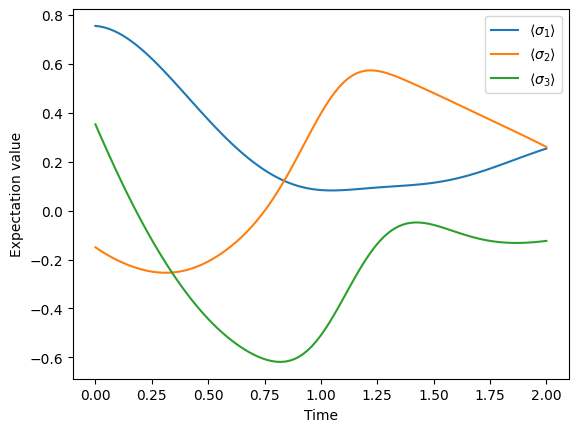

In [11]:
#colors = ['r', 'g', 'b']
fig, ax = plt.subplots()
for i in range(Liedim):
  ax.plot(t_points, Obsdat[1][i], label=fr"$\langle \sigma_{i+1} \rangle$")
  #ax.plot(t_points, Obsdat1[0][i], label=fr"$\langle \sigma_{i+1} \rangle$, high decay", linestyle='--', color=colors[i])

ax.set_xlabel("Time")
ax.set_ylabel("Expectation value")
ax.legend()
plt.show()

Now, compute the coefficients of the expansions:

$$
 \begin{array}{l}
i[ \alpha _{\mu } ,\alpha _{\nu }] =\sum\limits _{\eta } c_{\mu \nu \eta } \ \alpha _{\eta } ,\\
L_{k}^{\dagger } \alpha _{\nu } L_{k} -\frac{1}{2}\left\{L_{k}^{\dagger } L_{k} ,\alpha _{\nu }\right\} =d_{k\nu}I + \sum\limits _{\eta } b_{k\nu \eta } \ \alpha _{\eta }.
\end{array}
$$

In this case, $\alpha _{\nu }$ are the Pauli matrices, or the Kronecker product of Pauli matrices. I will consider the collapse operators $L_0 = \sigma_z$ and $L_1 = \sigma_-$. For the two-qubit system, I consider $L_0 = I \otimes \sigma_z$, $L_1 = \sigma_z \otimes I$, $L_2 = I \otimes \sigma_-$, $L_3 = \sigma_- \otimes I$.

In [12]:
if (Nqb==1):
    commcoeff = tc.zeros(Liedim, Liedim, Liedim, dtype=time.dtype)

    commcoeff[0,1,2] = -2
    commcoeff[2,0,1] = -2
    commcoeff[1,2,0] = -2

    commcoeff[1,0,2] = 2
    commcoeff[0,2,1] = 2
    commcoeff[2,1,0] = 2


    collcoef = tc.zeros(Ncoll, Liedim, Liedim, dtype=time.dtype)
    #L_0 = \sigma_z
    collcoef[0, 0, 0] = -2
    collcoef[0, 1, 1] = -2

    #L_1 = \sigma_-
    collcoef[1, 0, 0] = -0.5
    collcoef[1, 1, 1] = -0.5
    collcoef[1, 2, 2] = -1


    cnstcoef = tc.zeros(Ncoll, Liedim, dtype=time.dtype)
    cnstcoef[1, 2] = -1
#
#else:
#    commcoeff = tc.zeros(Liedim, Liedim, Liedim, dtype=time.dtype)
#    collcoef = tc.zeros(Ncoll, Liedim, Liedim, dtype=time.dtype)
#    cnstcoef = tc.zeros(Ncoll, Liedim, dtype=time.dtype)
#
#    #Index conversion to point to the basis element corresponding to \sigma_i x \sigma_j
#    def ic(i: int, j: int):
#        return i*4+j-1
#
#    for k in range(1,4):
#        for i in range(1,4):
#            j = 1 + i%3# We form the 3-tuple (i, j, l) such that it is a cyclic permutation of (1, 2, 3)
#            l = 3-(i+j)%3
#                
#            # [\sigma_k x \sigma_i, \sigma_k x \sigma_j] = Id x [\sigma_i, \sigma_j]
#            commcoeff[ic(k,i), ic(k,j), ic(0, l)] = -2
#            commcoeff[ic(k,i), ic(k,j), ic(0, l)] = 2
#
#            # [\sigma_i x \sigma_k, \sigma_j x \sigma_k] = [\sigma_i, \sigma_j] x Id
#            commcoeff[ic(i,k), ic(j,k), ic(l, 0)] = -2
#            commcoeff[ic(j,k), ic(i,k), ic(l, 0)] = 2
#            
#            # [\sigma_k x \sigma_i, Id x \sigma_j] = \sigma_k x [\sigma_i, \sigma_j]
#            commcoeff[ic(k,i), ic(0,j), ic(k, l)] = -2
#            commcoeff[ic(k,j), ic(0,i), ic(k, l)] = 2
#            
#            # [\sigma_i x Id, \sigma_j x \sigma_k] = [\sigma_i, \sigma_j] x \sigma_k
#            commcoeff[ic(i,0), ic(j,k), ic(l, k)] = -2
#            commcoeff[ic(j,0), ic(i,k), ic(l, k)] = 2
#
#    for i in range(4):
#        #Elements involving multiplication by \sigma_x or \sigma_y to the local collapse operator
#        for k in range(1,3):
#            #L_0 = Id x \sigma_z
#            collcoef[0, ic(i,k), ic(i,k)] = -2
#            #L_1 = \sigma_z x Id
#            collcoef[1, ic(k,i), ic(k,i)] = -2
#            #L_2 = Id x \sigma_-
#            collcoef[2, ic(i,k), ic(i,k)] = -0.5
#            #L_3 = \sigma_- x Id
#            collcoef[3, ic(k,i), ic(k,i)] = -0.5
#        #Elements involving multiplication by \sigma_z to the \sigma_- local collapse operator
#        collcoef[2, ic(i,3), ic(i,3)] = -1
#        collcoef[3, ic(3,i), ic(3,i)] = -1
#
#        cnstcoef[2, ic(i,3)] = -1
#        cnstcoef[3, ic(3,i)] = -1

100%|███████████████████████████████████████| 5000/5000 [01:54<00:00, 43.73it/s]


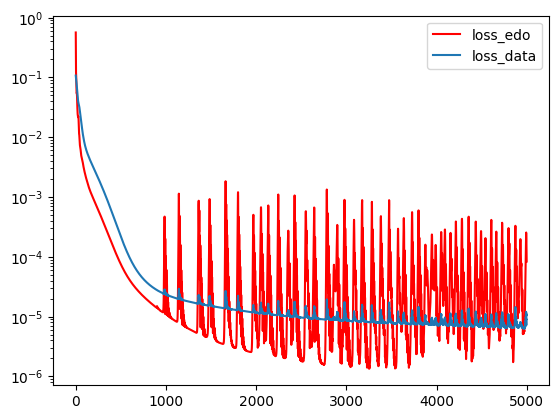

In [14]:
epocas  = 5000

LOSS    = []
LOSS1   = []
LOSS2   = []

#def model_fn(t):
#    return X_vector(t)
if (Nqb == 1):
    for epoca in tqdm(range(epocas)):
        ####### Forward pass #######
        y  = X_vector(time)

        Obs = y[:, :Nedo]
        Jctrl     = y[:, Nedo:Nedo+Nfield]        
        #Jz = Sz*tc.ones((N,1))

        # Run this to use control only in the x direction
        #Jy = tc.zeros((N,1))
        #Jt = tc.cat([Jctrl, Jy, Jz], dim=1)

        regys = (*Obs.split(1, dim=1), Jctrl)
        # If time is (N,1), autograd returns (N,1); expand via the Jacobian trick:
        # We still need per-component derivatives, so keep the loop-free cat approach:
        vars_list = list(Obs.split(1, dim=1))
        derivs = tc.cat(
            [tc.autograd.grad(v, time, grad_outputs=tc.ones_like(v),
                            create_graph=True)[0] for v in vars_list],
            dim=1,
        )
        
        #Loss_freq = ((tc.autograd.grad(wt, time, grad_outputs=tc.ones_like(wt), create_graph=True)[0])**2).sum()
        
        LOSS_edo = calculate_physics_loss(commcoeff, collcoef, cnstcoef, X_vector.parametro**2, Obs, derivs, Jctrl)
        LOSS_data = ((Odata - Obs)**2).mean()

        #LOSS_reg = (derivs**2).mean()

        # I will try with including a loss for the values of the control fields at the endpoints, assuming they are known beforehand
        LOSS_endpts = ((Jctrl[0,:] - tc.from_numpy(ctrls[0,:]))**2).mean() + ((Jctrl[-1,:] - tc.from_numpy(ctrls[-1,:]))**2).mean()

        ####### Loss total #######
        loss_i = LOSS_edo + LOSS_data + LOSS_endpts# + 0.05*LOSS_reg
        ####### Backpropagation #######
        opt.zero_grad()
        loss_i.backward()
        opt.step()
        LOSS1.append(LOSS_edo.cpu().detach().numpy())
        LOSS2.append(LOSS_data.cpu().detach().numpy())
else:
    for epoca in tqdm(range(epocas)):
        ####### Forward pass #######
        y  = X_vector(time)

        Obs = y[:, :Nedo]
        #JIX,JIY,JIZ,JXI,JYI,JZI
        Jctrl     = y[:, Nedo:Nedo+Nfield]
        
        #JXX,JXY,JXZ,JYX,JYY,JYZ,JZX,JZY,JZZ
        Jcnst = tc.from_numpy(np.array([1., 0., 0., 0., 1., 0., 0., 0., 1.], dtype=np.float32))

        #J0s = tc.zeros((N,1))
        #J1s = tc.ones((N,1))

        #Jt = tc.cat([Jctrl[:,:4], J1s, J0s, J0s, Jctrl[:,4:5], J0s, J1s, J0s, Jctrl[:,5:6], J0s, J0s, J1s], dim=1)
        # It is not the same Jctrl[:,4] as Jctrl[:,4:5], because the later returs a column and the former collapses a dimension

        regys = (*Obs.split(1, dim=1), Jctrl)#Jt)
        # If time is (N,1), autograd returns (N,1); expand via the Jacobian trick:
        # We still need per-component derivatives, so keep the loop-free cat approach:
        vars_list = list(Obs.split(1, dim=1))
        derivs = tc.cat(
            [tc.autograd.grad(v, time, grad_outputs=tc.ones_like(v),
                            create_graph=True)[0] for v in vars_list],
            dim=1,
        )
        
        #Loss_freq = ((tc.autograd.grad(wt, time, grad_outputs=tc.ones_like(wt), create_graph=True)[0])**2).sum()
        
        LOSS_edo = calculate_physics_loss(derivs, Jctrl, Jcnst, X_vector.parametro**2, Obs)
        LOSS_data = ((Odata - Obs)**2).mean()

        #LOSS_reg = (derivs**2).mean()

        # I will try with including a loss for the values of the control fields at the endpoints, assuming they are known beforehand
        LOSS_endpts = ((Jctrl[0,:] - tc.from_numpy(ctrls[0,:]))**2).mean() + ((Jctrl[-1,:] - tc.from_numpy(ctrls[-1,:]))**2).mean()

        ####### Loss total #######
        loss_i = LOSS_edo + LOSS_data + LOSS_endpts# + 0.05*LOSS_reg
        ####### Backpropagation #######
        opt.zero_grad()
        loss_i.backward()
        opt.step()
        LOSS1.append(LOSS_edo.cpu().detach().numpy())
        LOSS2.append(LOSS_data.cpu().detach().numpy())

plt.plot(LOSS1,'r-',label="loss_edo")
plt.plot(LOSS2,label="loss_data")
plt.yscale("log")
plt.legend()
plt.show()


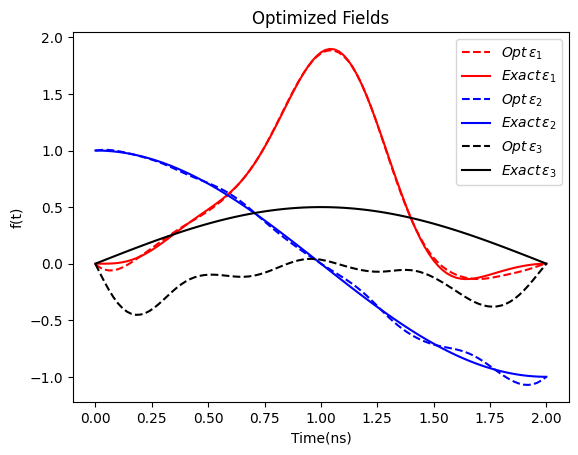

In [15]:
X_  = X_vector(time).detach().numpy()

w_opt=X_[:,-Nfield:]#, label="NN approx.")
gam_opt = (X_vector.parametro).detach().numpy()
colors = ['r', 'b', 'k'] if Nqb==1 else ['r', 'b', 'k', 'g', 'm', 'c']
fig, ax = plt.subplots()

for i in range(Nfield):
  ax.plot(t_points, w_opt[:,i], label=fr"$Opt \, \epsilon_{i+1}$", color=colors[i], linestyle='--')
  ax.plot(t_points, ctrls[:,i], label=fr"$Exact \, \epsilon_{i+1}$", color=colors[i])
  

plt.xlabel('Time(ns)')
plt.ylabel('f(t)')
#plt.plot(t_points, guess_field(time).detach().numpy(),"b-", label="Guess field")
plt.legend()
plt.title('Optimized Fields')
plt.show()

In [14]:
print(f"Optimized decay rates: {gam_opt**2},\nExact decay rates: {gams}")

Optimized decay rates: [0.29995203 0.44884723],
Exact decay rates: [0.3, 0.45]


Run this for one qubit.

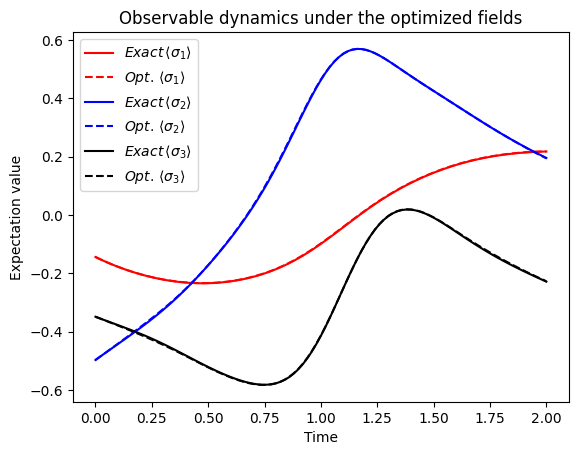

In [15]:
istate = nist-1

if (Nqb==1):

  rho0 = Instates[istate]
  H = [basis[2]*Sz]
  for i in range(Nfield):
      H.append([basis[i], w_opt[:, i]]) # QuTiP uses cubic spline interpolation for field_data

  c_ops = [np.abs(gam_opt[0])*qt.sigmaz(), np.abs(gam_opt[1])*qt.sigmam()]
  opts = {'store_states':True, 'atol':1.e-8, 'rtol':1.e-6}

  result_opt = qt.mesolve(H, rho0, t_points, e_ops=basis, c_ops=c_ops, options=opts)

  fig, ax = plt.subplots()
  for i in range(Liedim):
    ax.plot(t_points, Obsdat[istate][i], label=fr"$Exact \, \langle \sigma_{i+1} \rangle$", color=colors[i])
    ax.plot(t_points, result_opt.expect[i], label=fr"$Opt. \, \langle \sigma_{i+1} \rangle$", color=colors[i], linestyle='--')
    #ax.plot(t_points, X_[:,Liedim*istate + i], label=fr"$NN \langle \sigma_{i+1} \rangle$", color=colors[i], linestyle='--')

  ax.set_xlabel("Time")
  ax.set_ylabel("Expectation value")
  ax.legend()
  plt.title('Observable dynamics under the optimized fields')
  plt.show()
else:

  rho0 = Instates[istate]
  # The full Hamiltonian is defined as a list: 
  H = [qt.tensor(bas1q[1], bas1q[1]) + qt.tensor(bas1q[2], bas1q[2]) + qt.tensor(bas1q[3], bas1q[3])]

  for i in range(3):
      H.append([bas2q[i], ctrls[:, i]]) # QuTiP uses cubic spline interpolation for field_data

  for i in range(3):
      H.append([qt.tensor(bas1q[i+1], qt.qeye(2)), ctrls[:, i+3]])

  c_ops = []
  c_ops.append(np.sqrt(gam_opt[0])*qt.tensor(qt.qeye(2), qt.sigmaz()))
  c_ops.append(np.sqrt(gam_opt[1])*qt.tensor(qt.qeye(2), qt.sigmam()))
  c_ops.append(np.sqrt(gam_opt[2])*qt.tensor(qt.sigmaz(), qt.qeye(2)))
  c_ops.append(np.sqrt(gam_opt[3])*qt.tensor(qt.sigmam(), qt.qeye(2)))

  opts = {'store_states':True, 'atol':1.e-8, 'rtol':1.e-6}

  result_opt = qt.mesolve(H, rho0, t_points, e_ops=bas2q, c_ops=c_ops, options=opts)

  fig, ax = plt.subplots()
  for i in range(9,13):#range(Liedim):
    c = plt.gca()._get_lines.get_next_color()
    ax.plot(t_points, Obsdat[istate][i], label=fr"$Exact \, \langle \alpha_{i+1} \rangle$", color=c)
    ax.plot(t_points, result_opt.expect[i], label=fr"$Opt. \, \langle \alpha_{i+1} \rangle$", color=c, linestyle='--')
    #ax.plot(t_points, X_[:,Liedim*istate + i], label=fr"$NN \langle \sigma_{i+1} \rangle$", color=colors[i], linestyle='--')

  ax.set_xlabel("Time")
  ax.set_ylabel("Expectation value")
  ax.legend()
  plt.title('Observable dynamics under the optimized fields')
  plt.show()